# Laboratorul 2 — Exerciții
**Sisteme bazate pe cunoștințe · Înțelegerea datelor cu Python**

Aplicați fluxul de lucru EDA din `Lab2_Exemple_Rezolvate.ipynb` pe două seturi de date **noi**.

* **Partea A – Pinguini** (ghidată, 6 sarcini): un set de date real din Antarctica, cu valori lipsă și o surpriză (paradoxul lui Simpson).
* **Partea B – Detectivul de date** (5 sarcini + raport): un fișier smart-office cu **opt defecte introduse intenționat**. Găsiți-le pe toate.

Fișiere necesare în folderul notebook-ului: `penguins.csv`, `messy_office.csv`.

Dificultate: ★☆☆ încălzire · ★★☆ standard · ★★★ provocare. Autoverificările afișează ✅ sau ❌ + un indiciu. Numerele sunt comparate **după rotunjirea la 2 zecimale**, iar valorile așteptate sunt stocate ca amprente, deci nu puteți citi răspunsurile – trebuie să le calculați. Rulați sarcinile **în ordine**; un traceback roșu la o autoverificare înseamnă doar că sarcina nu este încă rezolvată.

**Predare:** *Kernel → Restart & Run All*, asigurați-vă că toate verificările sunt ✅ și că **răspunsurile scrise** (celulele markdown) și graficele sunt prezente. Predați fișierul `.ipynb`.

In [1]:
%pip install -r ../../requirements.txt

Note: you may need to restart the kernel to use updated packages.


In [2]:
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
PINK, BLUE, GREY = "#A33573", "#2A7F9E", "#9AA0A6"

def _norm(v):
    if isinstance(v, (bool, np.bool_)): return str(bool(v))
    if isinstance(v, (int, float, np.integer, np.floating)): return f"{float(v):.2f}"
    return str(v)

def check(label, condition, hint=""):
    """Autoverificare: bifă verde dacă condiția este îndeplinită, altfel un indiciu. Nu modificați."""
    print(("✅ " if condition else "❌ ") + label + ("" if condition else f"   → indiciu: {hint}"))

def check_value(label, value, code, hint=""):
    """Compară valoarea voastră (numerele rotunjite la 2 zecimale) cu amprenta valorii așteptate."""
    ok = hashlib.sha256(_norm(value).encode()).hexdigest()[:8] == code
    print(("✅ " if ok else "❌ ") + label + ("" if ok else f"   → indiciu: {hint}"))

# Partea A — Pinguini

## A1 · Prima privire  ★☆☆

**Context.** Trei specii de pinguini trăiesc pe trei insule ale Arhipelagului Palmer (Antarctica). Cercetătorii au măsurat *ciocul*, *aripioara* (flipper) și masa corporală a 344 de păsări. Încărcați `penguins.csv` într-un DataFrame numit `penguins` și răspundeți:

* `n_rows`, `n_cols` – dimensiunile tabelului (shape);
* `n_missing_total` – numărul total de celule lipsă;
* `col_most_missing` – **numele** coloanei cu cele mai multe valori lipsă.

Apoi priviți `penguins.info()` și `penguins.describe()` și scrieți o propoziție despre ce observați (intervale de valori, unități de măsură).

In [3]:
penguins = pd.read_csv('./penguins.csv')

n_rows, n_cols = penguins.shape
n_missing_total = penguins.isnull().sum().sum()
col_most_missing = 'sex'

In [4]:
n_rows, n_cols, n_missing_total, col_most_missing 

(344, 7, np.int64(19), 'sex')

In [5]:
penguins.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE


**Autoverificare**

In [6]:
check_value("n_rows", n_rows, "2c959c81", "shape[0]")
check_value("n_cols", n_cols, "b2337ecb", "shape[1]")
check_value("n_missing_total", n_missing_total, "df644619", "isnull().sum().sum()")
check_value("col_most_missing", col_most_missing, "98d44e13", "isnull().sum().idxmax()")

✅ n_rows
✅ n_cols
✅ n_missing_total
✅ col_most_missing


**Interpretarea voastră:** _scrieți aici_

## A2 · Ne putem baza pe date? Duplicate și rânduri cu valori lipsă  ★☆☆

* `n_dup` – numărul de **rânduri duplicate** (atenție: ce metodă pandas le detectează? `nunique()` nu le detectează!);
* `n_rows_with_nan` – câte rânduri au **cel puțin o** valoare lipsă (`isnull().any(axis=1)`);
* `penguins_c` – o copie a tabelului **fără** rândurile care au valori lipsă; `n_rows_clean` – lungimea ei.

**Gândiți-vă (scrieți într-o celulă markdown):** eliminarea a 11 rânduri din 344 este ieftină aici. Când *nu* ar fi o idee bună? (Indiciu: câte rânduri s-ar pierde dacă 30 % din celule ar lipsi aleatoriu pe 7 coloane?)

In [7]:
n_dup = penguins.duplicated().sum()
n_rows_with_nan = penguins.isnull().any(axis=1).sum()
penguins_c = penguins.copy().dropna()
n_rows_clean = len(penguins.dropna().notnull())

In [8]:
print(n_dup)
print(n_rows_with_nan)
print(penguins_c)
print(n_rows_clean)


0
11
    species     island  bill_length_mm  bill_depth_mm  flipper_length_mm  \
0    Adelie  Torgersen            39.1           18.7              181.0   
1    Adelie  Torgersen            39.5           17.4              186.0   
2    Adelie  Torgersen            40.3           18.0              195.0   
4    Adelie  Torgersen            36.7           19.3              193.0   
5    Adelie  Torgersen            39.3           20.6              190.0   
..      ...        ...             ...            ...                ...   
338  Gentoo     Biscoe            47.2           13.7              214.0   
340  Gentoo     Biscoe            46.8           14.3              215.0   
341  Gentoo     Biscoe            50.4           15.7              222.0   
342  Gentoo     Biscoe            45.2           14.8              212.0   
343  Gentoo     Biscoe            49.9           16.1              213.0   

     body_mass_g     sex  
0         3750.0    MALE  
1         3800.0  FEMALE  
2

**Autoverificare**

In [9]:
check_value("n_dup", n_dup, "561b2814", "duplicated().sum()")
check_value("n_rows_with_nan", n_rows_with_nan, "c6fffb51", "isnull().any(axis=1).sum()")
check_value("n_rows_clean", n_rows_clean, "24d44448", "dropna()")
check('penguins_c nu mai are valori lipsă', penguins_c.isnull().sum().sum() == 0, 'dropna()')

✅ n_dup
✅ n_rows_with_nan
✅ n_rows_clean
✅ penguins_c nu mai are valori lipsă


**Interpretarea voastră:** _scrieți aici_

## A3 · O variabilă: distribuții  ★★☆

Folosind `penguins_c`:

1. Desenați **histograma cu KDE** pentru `body_mass_g` și pentru `flipper_length_mm` (două subgrafice).
2. `skew_mass` – asimetria (skewness) lui `body_mass_g` (rotunjită la 2 zecimale).
3. `majority_share` – ponderea **celei mai frecvente specii** printre cele 333 de păsări (un număr între 0 și 1) – folosiți `value_counts(normalize=True)`.
4. Faceți un **count plot** al speciilor. Este setul de date echilibrat?

**Interpretați:** histograma masei corporale pare *bimodală* (două cocoașe), deși asimetria este mică. Ce vă spune asta despre folosirea exclusivă a numărului de asimetrie? (Indiciu: explicația o veți vedea la sarcina A5.)

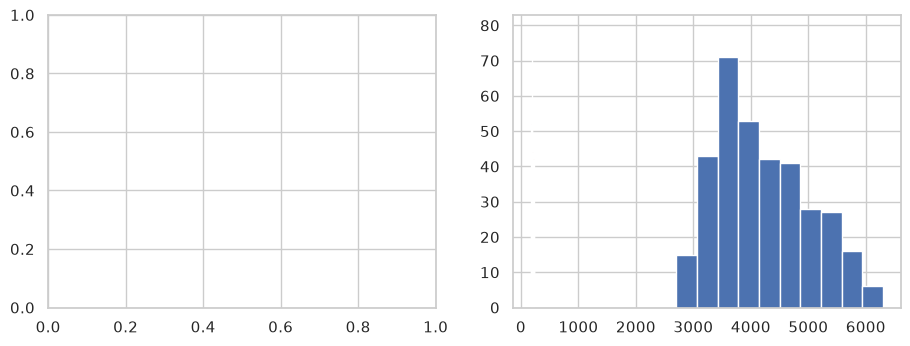

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
plt.hist(round(penguins['body_mass_g'], 2))
plt.hist(round(penguins['flipper_length_mm'], 2))
# histogramele aici

skew_mass = round(penguins_c['body_mass_g'].skew(), 2)
majority_share =  round(penguins_c['species'].value_counts(normalize=True).iloc[0], 2)

In [11]:
print(skew_mass)
print(majority_share)

0.47
0.44


**Autoverificare**

In [12]:
check_value("skew_mass", skew_mass, "b440d5b1", "round(..., 2) pentru .skew()")
check_value("majority_share", majority_share, "26ccbcee", "value_counts(normalize=True).iloc[0]")

✅ skew_mass
✅ majority_share


**Interpretarea voastră:** _scrieți aici_

## A4 · O variabilă pe grupuri și valori aberante (outlier)  ★★☆

1. Desenați un **boxplot** al lui `body_mass_g` pentru fiecare specie (`x="species"`).
2. `heaviest_species` – numele speciei cu cea mai mare **medie** a masei corporale (`groupby`).
3. `mass_ratio` – masa medie a speciei Gentoo împărțită la masa medie a speciei Adelie (2 zecimale).
4. Aplicați **regula IQR** (Q1 − 1,5·IQR, Q3 + 1,5·IQR) fiecăreia dintre cele patru coloane numerice și memorați numărul **total** de valori marcate în `n_outliers_total`. (Scrieți o funcție mică – ați făcut asta în exemplul rezolvat.)

**Interpretați:** raportați rezultatul pasului 4 într-o propoziție. Este „0 valori aberante" o veste bună sau un motiv să verificați altceva?

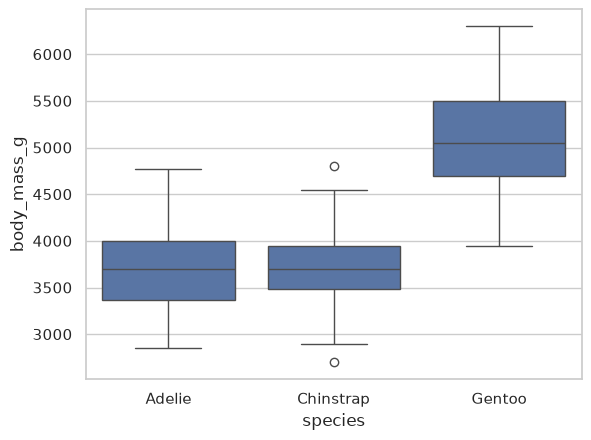

In [13]:
# boxplot

sns.boxplot(data=penguins_c, x="species", y="body_mass_g")

heaviest_species = penguins_c.groupby('species')['body_mass_g'].mean().idxmax()
species_means = penguins_c.groupby('species')['body_mass_g'].mean()
mass_ratio = round(species_means['Gentoo' ] / species_means['Adelie'], 2)
# mass_ratio = round(mean(gentoo / ), 2)

def count_iqr_outliers(s):
    k = 1.5
    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    iqr = q3 - q1
    low = q1 - k*iqr
    hig = q3 + k*iqr
    return int(((s < low) | (s > hig)).sum())

cols = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']
n_outliers_total = sum(count_iqr_outliers(penguins_c[col]) for col in cols)

In [14]:
heaviest_species, species_means, mass_ratio, penguins.columns

('Gentoo',
 species
 Adelie       3706.164384
 Chinstrap    3733.088235
 Gentoo       5092.436975
 Name: body_mass_g, dtype: float64,
 np.float64(1.37),
 Index(['species', 'island', 'bill_length_mm', 'bill_depth_mm',
        'flipper_length_mm', 'body_mass_g', 'sex'],
       dtype='str'))

**Autoverificare**

In [15]:
check_value("heaviest_species", heaviest_species, "b5e90cdf", "groupby('species')['body_mass_g'].mean().idxmax()")
check_value("mass_ratio", mass_ratio, "64ee787d", "media Gentoo / media Adelie")
check_value("n_outliers_total", n_outliers_total, "561b2814", "suma, pe cele 4 coloane numerice, a numărătorilor IQR")

✅ heaviest_species
✅ mass_ratio
✅ n_outliers_total


**Interpretarea voastră:** _scrieți aici_

## A5 · Două variabile — și o capcană celebră  ★★★

Au păsările cu **cioc mai lung** și **cioc mai adânc**?

1. `r_all` – corelația Pearson dintre `bill_length_mm` și `bill_depth_mm` pe **toți** pinguinii din `penguins_c` (2 zecimale).
2. Desenați un grafic scatter (`sns.scatterplot`) al celor două variabile **fără** culori, apoi încă o dată **colorat după specie** (`hue="species"`).
3. `r_min_within` – calculați aceeași corelație **în interiorul fiecărei specii** și memorați cea mai **mică** dintre cele trei valori (2 zecimale).
4. `simpson` – `True` dacă corelația globală este negativă **și** toate cele trei corelații din interiorul speciilor sunt pozitive.

**Interpretați (important!):** explicați în 2–3 propoziții de ce semnul global este opusul semnului din interiorul fiecărui grup. Acesta este **paradoxul lui Simpson**: o tendință din datele agregate se poate inversa atunci când datele sunt împărțite pe grupuri. Ce variabilă se *ascunde* în spatele rezultatului? Ce ar fi mers prost dacă ați fi analizat doar corelația globală?

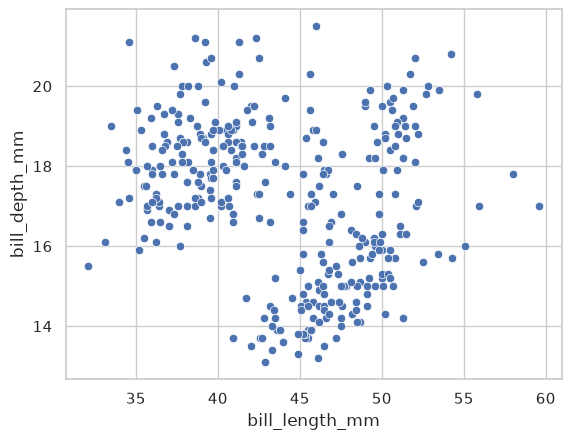

In [16]:
S1 = penguins_c['bill_depth_mm']
S2 = penguins_c['bill_length_mm']

r_all = S2.corr(S1)

# grafice scatter
sns.scatterplot(data=penguins_c, x='bill_length_mm', y='bill_depth_mm')

r_min_within = penguins_c.groupby('species').apply(lambda h: h['bill_length_mm'].corr(h['bill_depth_mm']))
simpson = r_all < 0

In [17]:
(r_all, r_min_within, simpson)

(np.float64(-0.22862563591302934),
 species
 Adelie       0.385813
 Chinstrap    0.653536
 Gentoo       0.654023
 dtype: float64,
 np.True_)

**Autoverificare**

In [18]:
check_value("r_all", r_all, "3a547418", "Series.corr(altă_serie)")
check_value("r_min_within", r_min_within, "b1188979", "groupby('species'), apoi .corr în fiecare grup; luați minimul")
check_value("simpson", simpson, "3cbc87c7", "r_all < 0 și toate corelațiile din grupuri > 0")

✅ r_all
❌ r_min_within   → indiciu: groupby('species'), apoi .corr în fiecare grup; luați minimul
✅ simpson


**Interpretarea voastră:** _scrieți aici_

## A6 · Mai multe variabile și propriile concluzii  ★★☆

1. Desenați o **hartă termică (heat-map) mascată a corelațiilor** pentru cele patru coloane numerice din `penguins_c` (paletă divergentă, centrată pe 0, cu adnotări).
2. `top_pair` – un **tuplu sortat** cu numele celor două variabile numerice cu cea mai mare corelație în valoare absolută, de exemplu `("a", "b")`; `top_r` – corelația lor (2 zecimale).
3. Desenați un **pair plot** al coloanelor numerice, colorat după `species`.
4. Într-o celulă markdown scrieți **trei concluzii** pe care le-ar putea folosi un zoolog, fiecare cu un număr.

In [21]:
# heat-map
sns.heatmap(data=penguins_c)


top_pair = ...
top_r = ...

# pair plot

ValueError: could not convert string to float: 'Adelie'

**Autoverificare**

In [ ]:
check_value("top_pair", top_pair, "411f62fa", "căutați cel mai mare |r| sub diagonală")
check_value("top_r", top_r, "36c219b3", "round(r, 2)")

**Interpretarea voastră:** _scrieți aici_

# Partea B — Detectivul de date

## B1 · Primiți fișierul  ★☆☆

Un coleg vă trimite `messy_office.csv`: **două zile (14–15 aprilie) de măsurători pe minut dintr-un alt birou**, cu aceleași coloane ca setul de date smart-office din curs. Ceva nu este în regulă cu el – sarcina voastră este să **aflați ce, înainte să-l folosească cineva**.

Regulile jocului: **diagnosticați; nu reparați încă** (repararea valorilor lipsă și a zgomotului este subiectul cursurilor următoare). Încărcați fișierul cu timestamp-ul interpretat ca dată (`parse_dates=["timestamp"]`) și memorați numărul de rânduri în `n_rows`.

*Dimensiunea așteptată dacă logger-ul ar fi funcționat perfect: 2 zile × 1440 min = 2880 de rânduri.*

In [29]:
office = pd.read_csv('./messy_office.csv')
n_rows = office.shape[0]

In [31]:
n_rows

2875

In [32]:
office.head()

,timestamp,temp_c,humidity_pct,co2_ppm,occupancy,temp_out_c
0,2026-04-14 00:00:00,17.54,53.8,461.0,0,5.99
1,2026-04-14 00:01:00,17.41,54.2,453.0,0,6.00
2,2026-04-14 00:02:00,17.56,56.1,452.0,0,6.00
3,2026-04-14 00:03:00,17.49,55.7,452.0,0,5.97
4,2026-04-14 00:04:00,17.60,57.4,452.0,0,5.96


**Autoverificare**

In [33]:
check_value("n_rows", n_rows, "201b6f00", "len(office)")

✅ n_rows


## B2 · Defectul 1: rânduri duplicate  ★☆☆

`n_dup_rows` – numărul de rânduri duplicate exacte. Apoi creați `office_u` = tabelul **fără** duplicate (cu indexul resetat) și folosiți `office_u` pentru **toate sarcinile următoare**.

In [39]:
n_dup_rows = office.duplicated().sum()
office_u = office.drop_duplicates()

In [ ]:
print(n_dup_rows, len(office_u)) 

40 2835


**Autoverificare**

In [38]:
check_value("n_dup_rows", n_dup_rows, "f29c3d3c", "duplicated().sum()")

✅ n_dup_rows


## B3 · Defectele 2 și 3: valori lipsă și pași de timp lipsă  ★★☆

* `n_missing_co2` – valorile CO₂ lipsă din `office_u`;
* `longest_gap_min` – cea mai lungă **succesiune de valori CO₂ lipsă consecutive** (în minute). *Indiciu:* `na = office_u["co2_ppm"].isna()`; un grup nou începe de fiecare dată când o valoare **nu** este lipsă: `na.groupby((~na).cumsum()).sum().max()`;
* `n_missing_humidity` – valorile de umiditate lipsă;
* `n_missing_timestamps` – câte **minute lipsesc complet din fișier** (rânduri care nu există deloc, nu NaN!). *Indiciu:* comparați `pd.date_range(start, end, freq="min")` cu timestamp-urile pe care le aveți.

**Gândiți-vă:** de ce este mai greu de observat un *rând* lipsă decât un `NaN`?

In [100]:
n_missing_co2 = int(office_u.isna().sum().sum())

na = office_u["co2_ppm"].isna()
longest_gap_min = na.groupby((~na).cumsum()).sum().max()
n_missing_humidity = office_u['humidity_pct'].isna().sum()

start = '2026-04-14 00:00:00'
end = '2026-04-15 23:59:59'
total_time = len(pd.date_range(start=start, end=end, freq="min"))
n_missing_timestamps = total_time - len(office_u)

In [101]:
n_missing_co2, longest_gap_min, n_missing_humidity, total_time, n_missing_timestamps

(87, np.int64(75), np.int64(12), 2880, 45)

**Autoverificare**

In [102]:
check_value("n_missing_co2", n_missing_co2, "5a711012", "isna().sum()")
check_value("longest_gap_min", longest_gap_min, "5a711012", "vedeți indiciul cu groupby((~na).cumsum())")
check_value("n_missing_humidity", n_missing_humidity, "143dac93", "isna().sum()")
check_value("n_missing_timestamps", n_missing_timestamps, "bc7a1ad0", "len(intervalul complet) - numărul de timestamp-uri distincte")

❌ n_missing_co2   → indiciu: isna().sum()
✅ longest_gap_min
✅ n_missing_humidity
✅ n_missing_timestamps


## B4 · Defectele 4–6: valori imposibile  ★★☆

Folosiți `describe()` și bunul simț fizic:

* `n_temp_impossible` – măsurători `temp_c` **peste 50 °C** (un birou nu este niciodată atât de cald; poate unitatea de măsură este greșită – ce ar putea însemna 64–68?);
* `n_humidity_over_100` – umiditate relativă **peste 100 %** (imposibil; ce folosesc oamenii adesea drept *cod pentru valoare lipsă*?);
* `n_negative_occ` – un **număr negativ de persoane**.

Desenați `temp_c` în timp (`office_u.set_index("timestamp")["temp_c"].plot()`) și descrieți ce vedeți.

In [103]:
n_temp_impossible = ...
n_humidity_over_100 = ...
n_negative_occ = ...

**Autoverificare**

In [ ]:
check_value("n_temp_impossible", n_temp_impossible, "5e0de86a", "(temp_c > 50).sum()")
check_value("n_humidity_over_100", n_humidity_over_100, "4cc019de", "(humidity_pct > 100).sum()")
check_value("n_negative_occ", n_negative_occ, "9ae1524b", "(occupancy < 0).sum()")

## B5 · Defectele 7 și 8: un senzor înghețat și vârfuri  ★★★

Acestea nu se văd în `describe()`; trebuie să **priviți semnalul**.

1. Desenați CO₂ pe cele două zile (`figsize=(12, 3.5)`). Două lucruri par greșite: un **segment plat** și câteva **vârfuri izolate**.
2. `longest_flat_run` – cea mai lungă succesiune de **valori CO₂ consecutive identice** (în rânduri). *Indiciu:* `run_id = (s != s.shift()).cumsum()` crește de fiecare dată când valoarea se schimbă; apoi `s.groupby(run_id).size().max()`. În datele normale acest număr este mic (câteva minute) – de ce? (Gândiți-vă la zgomot.)
3. `n_spikes` – numărul de valori CO₂ peste **1500 ppm** (intervalul normal al acestei camere este ~430–800 ppm).

**Gândiți-vă:** sunt vârfurile *erori* sau *evenimente reale*? Ce variabilă suplimentară din tabel v-ar putea ajuta să decideți? (Priviți `occupancy` în momentele vârfurilor.)

In [ ]:
# grafic

longest_flat_run = ...
n_spikes = ...

**Autoverificare**

In [ ]:
check_value("longest_flat_run", longest_flat_run, "14e0ee87", "s.groupby((s != s.shift()).cumsum()).size().max()")
check_value("n_spikes", n_spikes, "a97491cd", "(s > 1500).sum()")

## B6 · Raportul de defecte și o curățare minimă  ★★★
**1. Raportul de defecte.** Construiți un DataFrame `report` cu câte un rând pentru fiecare defect și coloanele `defect`, `how_detected`, `rows_affected`, `suggested_treatment`. Completați toate cele **opt** defecte pe care le-ați găsit (folosiți numerele din sarcinile de mai sus). Pentru *suggested_treatment* alegeți dintre: *eliminare*, *conversie unitate*, *înlocuire cod cu NaN*, *interpolare ulterioară*, *filtrare ulterioară*, *întrebare la proprietar*. 

**2. Curățare minimă (doar ce nu necesită modelare).** Creați `office_clean` din `office_u` prin:
* convertirea temperaturilor de peste 50 °C din °F în °C: `(t − 32) · 5/9`;
* înlocuirea valorilor de umiditate peste 100 cu `NaN`;
* înlocuirea ocupării negative cu `NaN`.

Lăsați valorile lipsă, segmentul înghețat și vârfurile **neatinse** – decizia cum să fie tratate este subiectul Cursurilor 4–6.

In [ ]:
report = pd.DataFrame({
    "defect": [...],
    "how_detected": [...],
    "rows_affected": [...],
    "suggested_treatment": [...],
})

office_clean = office_u.copy()
# conversiile aici

**Autoverificare**

In [ ]:
check("report are cele 4 coloane cerute", {"defect", "how_detected", "rows_affected", "suggested_treatment"} <= set(report.columns))
check("report listează cel puțin 8 defecte", len(report) >= 8, "un rând pe defect (duplicate, lipsă, timestamp-uri, unitate, cod, negativ, înghețat, vârfuri)")
check("nicio temperatură peste 50 °C", office_clean["temp_c"].max() < 50, "convertiți doar rândurile în care temp_c > 50")
check("valorile convertite sunt plauzibile (15-30 °C)", office_clean["temp_c"].between(15, 30).all(), "(t - 32) * 5/9")
check("umiditate ≤ 100", office_clean["humidity_pct"].max() <= 100)
check("occupancy ≥ 0", office_clean["occupancy"].min() >= 0)
check("neatins: numărul de NaN din CO2 este neschimbat", office_clean["co2_ppm"].isna().sum() == office_u["co2_ppm"].isna().sum(), "nu completați încă golurile din CO2")

## Bonus (opțional) 🎁
1. Rulați un **raport de profilare** (`fg-data-profiling`, vedeți exemplul rezolvat) pe `messy_office.csv`. Care dintre cele opt defecte ale voastre sunt semnalate automat? Care sunt ratate?
2. Repetați *verificarea Simpson* pe datele smart-office: este corelația dintre `temp_c` și `co2_ppm` pe toată ziua aceeași cu corelația calculată **separat pentru orele de lucru (08–18) și pentru noapte**? Desenați ambele cazuri.

## Reflecție
* Care defecte ar fi fost vizibile într-un **tabel** (`head`, `describe`) și care doar într-un **grafic**?
* Un model antrenat pe `messy_office.csv` fără curățare – care defect ar dăuna cel mai mult și de ce?